## <div style="direction:rtl;text-align:right">  بخش اول؛ تحلیل و جداسازی رنگ‌ها در تصاویر دیجیتال </div>

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

<div style="direction:rtl;text-align:right">
ما برای پردازش تصویرهای ورودی از کتابخانه OpenCV استفاده کرده‌ایم پس cv2 را ایمپورت می‌کنیم.
<br/>
همچنین برای نمایش تصویرها از کتابخانه matplotlib استفاده می‌کنیم.
</div>

#### <div style="direction:rtl;text-align:right"> سوال اول؛ بررسی مشخصات تصویر </div>

In [3]:
img = cv2.imread('Peppers.png')
print('type:', type(img))
print('dimension:', img.shape)

type: <class 'numpy.ndarray'>
dimension: (1024, 1536, 3)


<div style="direction:rtl;text-align:right">
با دستور imread می‌توانیم تصویر را بخوانیم.
<br/>
تصویر در قالب یک N-dimensional Array خوانده می‌شود که یک آرایه‌ی NumPy چند بعدی از مقادیر است. 
<br/>
دستور shape تعداد خانه‌های هر بعد از آرایه را نمایش می‌دهد. این مقادیر به این معنی است که تصویر ما دارای طول و عرض 1024 در 1536 پیکسلی است و 3 کانال رنگی RGB دارد.
<br/>
اگر تصویر خوانده شده را مستقیما با matplotlib نمایش دهیم، تصویری مانند تصویر سمت چپ خواهیم داشت که از نظر رنگی درست نیست.
</div>

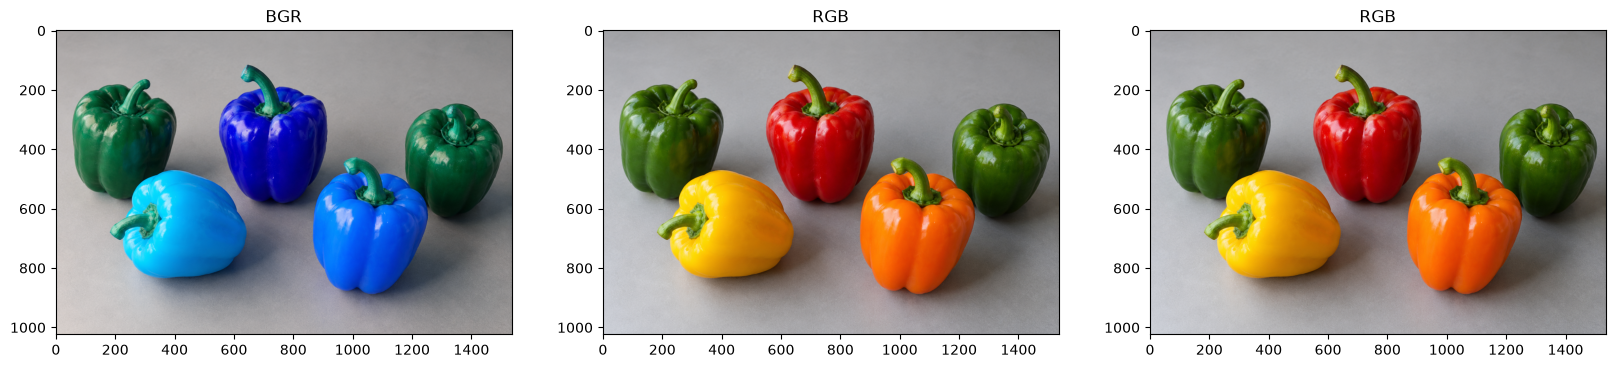

In [4]:
plt.figure(figsize=[20,5])
plt.subplot(131); plt.imshow(img); plt.title("BGR");

plt.subplot(132); plt.imshow(img[:,:,::-1]); plt.title("RGB"); # برعکس کردن ترتیب کانال‌ها

img2 = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # استفاده از تابع آماده
plt.subplot(133); plt.imshow(img2); plt.title("RGB");

<div style="direction:rtl;text-align:right">
دلیل این اتفاق این است که OpenCV به طور پیش فرض تصاویر را بصورت BGR می‌خواند. اما matplotlib ترتیب کانال‌های تصاویر را RGB رسم می‌کند.
<br/>
بنابراین اگر مستقیما همان تصویر را نمایش دهیم،‌ جای کانال‌های R و B جابجا خواهد بود و رنگ‌بندی تصویر متفاوت می‌شود.
<br/>
برای نمایش درست تصویر باید ترتیب کانال‌های رنگی را جابجا کنیم. می‌توانیم بصورت دستی کانال‌های ورودی را برعکس به matplotlib بدهیم یا از توابع داخلی OpenCV استفاده کنیم.
</div>

In [5]:
B, G, R = cv2.split(img)
print('Red:\t min:', R.min(), '\tmax:', R.max())
print('Green:\t min:', G.min(), '\tmax:', G.max())
print('Blue:\t min:', B.min(), '\tmax:', B.max())

Red:	 min: 0 	max: 255
Green:	 min: 0 	max: 253
Blue:	 min: 0 	max: 229


<div style="direction:rtl;text-align:right">
برای دیدن محدوده مقادیر هر کانال، هر کانال رنگی را بطور جداگانه ذخیره کردیم تا بتوانیم مقدار مینیمم و ماکسیمم هر کدام را جداگانه نمایش دهیم.
<br/>
با استفاده از تابع داخل min و max پایتون، کمترین و بیشترین مقدار هر کانال رنگی را بدست آورده‌ایم.
</div>

#### <div style="direction:rtl;text-align:right"> سوال دوم؛ تبدیل انواع تصاویر </div>
<div style="direction:rtl;text-align:right">تصویر ورودی را به سه حالت RGB، Grayscale و Binary تبدیل می‌کنیم.</div>

In [6]:
#img_bgr = cv2.imread("Peppers.png")                 # OpenCV تصویر را به ترتیب BGR می‌خواند
#img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)  # برای نمایش درست در matplotlib
img_bgr = img
img_rgb = img2

In [7]:
# 1) RGB: فقط ترتیب کانال‌ها را از BGR به RGB تغییر می‌دهیم
# (img_rgb در سلول اول ساخته شد)

# 2) Grayscale
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# 3) Binary: آستانه‌گذاری به روش Otsu
threshold, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print("Binary method : Otsu thresholding")
print("Threshold value:", threshold)

Binary method : Otsu thresholding
Threshold value: 116.0


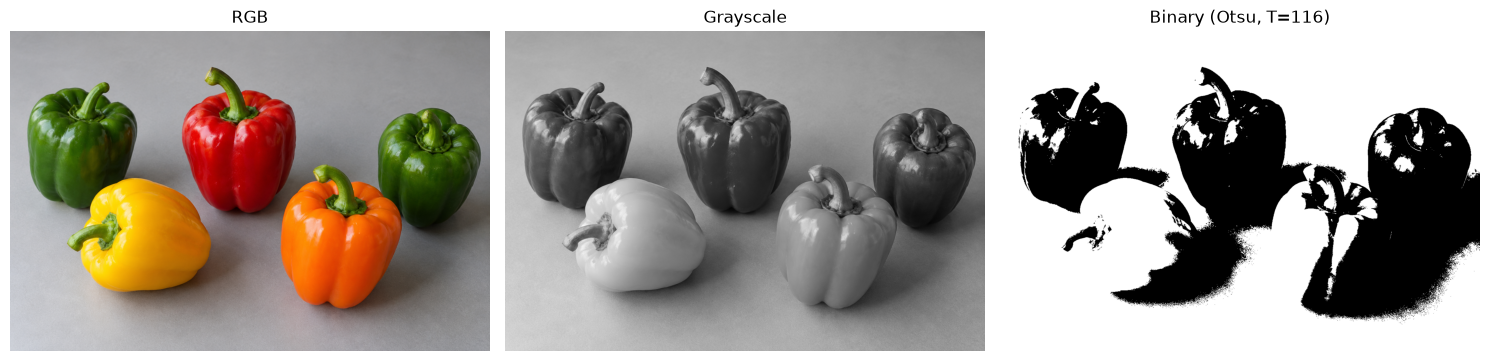

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_rgb)
axes[0].set_title("RGB")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale")

axes[2].imshow(binary, cmap="gray")
axes[2].set_title(f"Binary (Otsu, T={threshold:.0f})")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

<div style="direction:rtl;text-align:right">

##### روش تولید تصویر دودویی و آستانه
- از **آستانه‌گذاری Otsu** استفاده شد. این روش آستانه را خودکار و از روی هیستوگرام انتخاب می‌کند، به‌طوری که واریانس بین دو دسته (پیکسل‌های تیره و روشن) بیشینه شود.
- مقدار آستانه انتخاب‌شده در خروجی سلول ۳ چاپ شده است (پیکسل‌های بزرگ‌تر از آستانه ۲۵۵ و بقیه ۰ می‌شوند).
- دلیل انتخاب: نیازی به حدس زدن دستی آستانه (مثلاً ۱۲۷) نیست و به شرایط روشنایی خود تصویر وابسته است.

##### چه اطلاعاتی از دست می‌رود؟
**رنگی ← خاکستری:**
- اطلاعات رنگ (Hue و Saturation) از بین می‌رود و سه کانال به یک کانال تبدیل می‌شود (فقط شدت روشنایی می‌ماند، طبق رابطه Gray = 0.299R + 0.587G + 0.114B).
- رنگ‌های متفاوتی که روشنایی مشابه دارند (مثلاً فلفل قرمز و سبز) ممکن است خاکستری یکسان یا نزدیک بگیرند و تفکیک‌شان سخت شود.

**خاکستری ← دودویی:**
- از ۲۵۶ سطح روشنایی فقط دو سطح (۰ و ۲۵۵) می‌ماند، پس سایه‌روشن‌ها، گرادیان‌ها و حس عمق/حجم از بین می‌رود.
- جزئیات ظریف و بافت (Texture) حذف می‌شود و نتیجه به مقدار آستانه حساس است.

این تبدیل‌ها **بازگشت‌ناپذیرند**: از روی تصویر دودویی نمی‌توان تصویر رنگی اصلی را بازسازی کرد.</div>

#### <div style="direction:rtl;text-align:right"> سوال سوم؛ بررسی فضاهای رنگی RGB و HSV </div>

<div style="direction:rtl;text-align:right">
برای تفکیک کانال‌های رنگی تصویر RGB کافیست در هر مرحله فقط یکی از ابعاد تصویر را نمایش دهیم.
    <br/>
در تصاویر هر کانال، نقاطی که تیره تر هستند، یعنی مقدار کمتری دارند و رنگ مد نظر در آن نقطه کمتر است. همچنین نقاط روشن تر مقادیر بیشتر هستند و رنگ بیشتری از آن کانال رنگی خاص در آن نقطه وجود دارد.
    <br/>
مثلا در کانال Blue می‌بینیم که نقاط روی فلفل‌ها بسیار تیره است. این یعنی مقدار رنگ آبی در این نقاط بسیار کم است که با تصویر اصلی نیز همخوانی دارد.
</div>

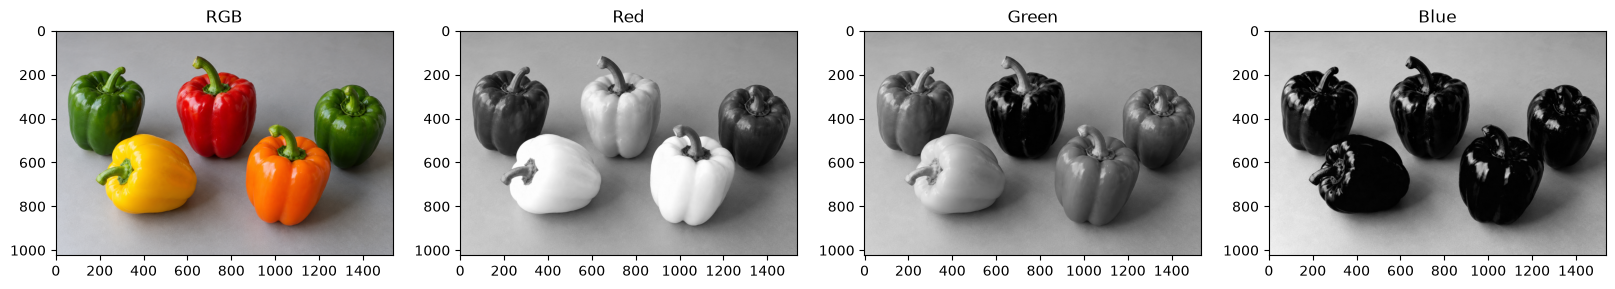

In [9]:
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=[20,8])
plt.subplot(141); plt.imshow(RGB_img); plt.title("RGB");
plt.subplot(142); plt.imshow(RGB_img[:,:,0], cmap='gray'); plt.title("Red");
plt.subplot(143); plt.imshow(RGB_img[:,:,1], cmap='gray'); plt.title("Green");
plt.subplot(144); plt.imshow(RGB_img[:,:,2], cmap='gray'); plt.title("Blue");

<div style="direction:rtl;text-align:right">
برای تبدیل تصویر به HSV از تابع داخلی OpenCV استفاده کردیم. باید توجه داشت که وقتی تصویر را به HSV تبدیل می‌کنیم، دیگر با matplotlib قابل رسم نیست چرا که matplotlib‌ فقط RGB می‌پذیرد. بنابراین اگر تصویر HSV را به matplotlib بدهیم، تصویر سمت چپ را خواهیم داشت که رنگ بندی درستی ندارد چرا که ابعاد تصویر اصلا مقادیر RGB نیستند اما matplotlib آنها را بعنوان RGB می‌خواند.
    <br/>
هر یک از کانال‌ها HSV به طور جداگانه رسم شده‌اند. مانند تصاویر قبلی، نقاط تیره تر به معنی مقدار کمتر و نقاط روشن تر مقادیر بیشتر هستند.
    <br/>
مثلا نقاط روی فلفل‌ها که نقاط رنگی تصویر هستند، دارای Saturation بالا هستند. سایر نقاط تصویر که غالبا خاکستری‌اند، مقدار Sqturation پایین و نزدیک به صفری دارند که با تصویر اصلی نیز همخوانی دارد.
    </div>

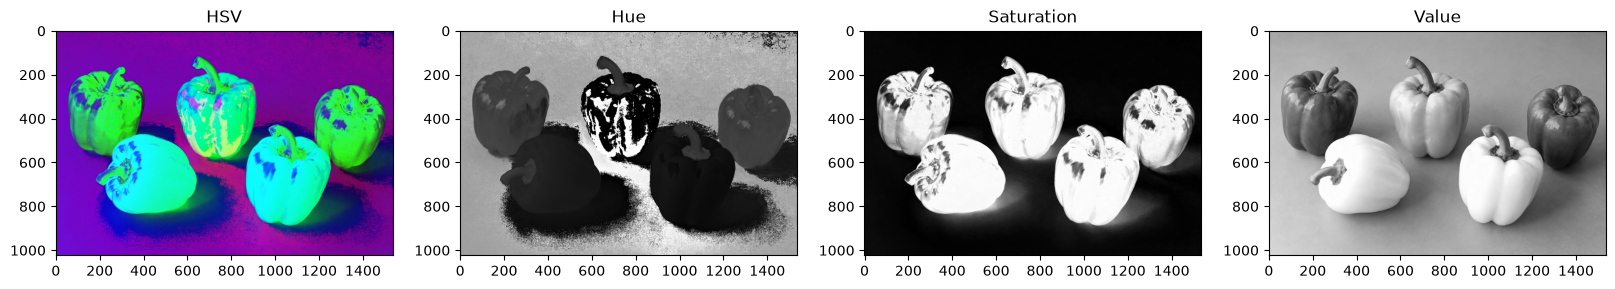

In [10]:
HSV_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

plt.figure(figsize=[20,8])
plt.subplot(245); plt.imshow(HSV_img); plt.title("HSV");
plt.subplot(246); plt.imshow(HSV_img[:,:,0], cmap='gray'); plt.title("Hue");
plt.subplot(247); plt.imshow(HSV_img[:,:,1], cmap='gray'); plt.title("Saturation");
plt.subplot(248); plt.imshow(HSV_img[:,:,2], cmap='gray'); plt.title("Value");

<div style="direction:rtl;text-align:right">
در فضای رنگی RGB، تصاویر در قالب سه کانال رنگی اصلی نور ذخیره می‌شوند. در این فضا، اطلاعات رنگ و روشنایی تصویر با یکدیگر ترکیب شده‌اند و معمولا تغییر روشنایی تصویر، باعث ایجاد تغییر در هر سه کانال می‌شود. در فضای رنگی RGB برای تشخیص رنگ هر نقطه از تصویر، به هر سه کانال نیاز داریم.
</div>

<div style="direction:rtl;text-align:right">
در فضای رنگی HSV، تصویر در قالب سه مقدار فام رنگ (Hue)، غلظت یا شدت رنگ (Saturation) و میزان روشنایی (Value) ذخیره می‌شود. در این فضای رنگی، مقدار رنگ از اطلاعات مربوط به روشنایی جدا شده که امکان بررسی رنگ اجسام با تمرکز فقط بر کانال Hue را می‌دهد. بنابراین فضای رنگی HSV برای تفکیک و بررسی رنگ اجسام مناسب تر است زیرا مؤلفه Hue امکان شناسایی نوع رنگ را بدون وابستگی مستقیم به شدت روشنایی فراهم می‌کند.
</div>

<div style="direction:rtl;text-align:right">
برای مثال، اگر بخواهیم تمام اجسام قرمز موجود در یک تصویر را شناسایی کنیم، در فضای HSV می‌توانیم محدوده مشخصی از Hue را انتخاب کنیم و با استفاده از Saturation و Value نیز رنگ‌های کم‌اشباع یا بسیار تاریک را حذف کنیم.
در مقابل، در فضای RGB تشخیص یک رنگ خاص، نیازمند بررسی هر سه کانال رنگی و تعیین روابط بین آنهاست..</div>

#### <div style="direction:rtl;text-align:right"> سوال چهارم؛ جداسازی نواحی رنگی </div>

<img src="HSV_color_mode.png" />

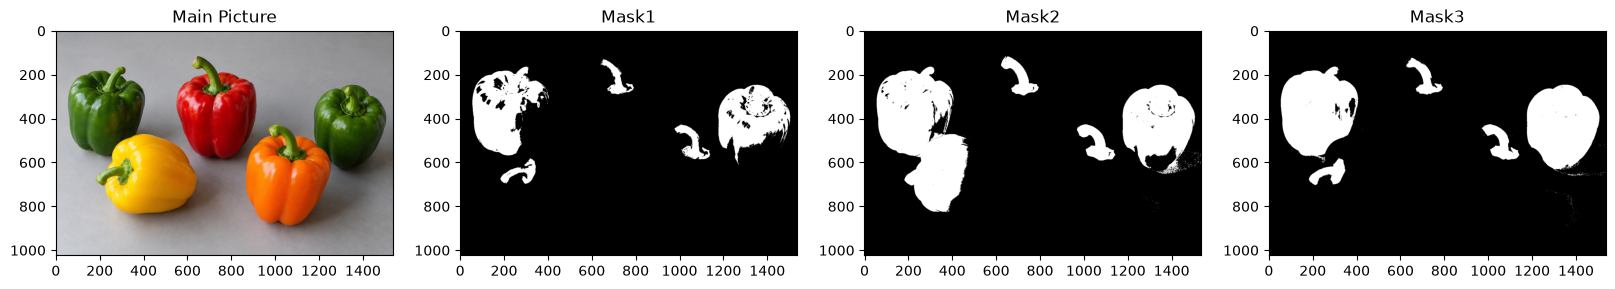

In [11]:
start_1 = np.array([35, 50, 50]); end_1 = np.array([85, 255, 255]); mask_1 = cv2.inRange(HSV_img, start_1, end_1); # [H, S, V]
start_2 = np.array([20, 30, 30]); end_2 = np.array([85, 255, 255]); mask_2 = cv2.inRange(HSV_img, start_2, end_2);
start_3 = np.array([30, 10, 10]); end_3 = np.array([85, 255, 255]); mask_3 = cv2.inRange(HSV_img, start_3, end_3);

plt.figure(figsize=[20,8])
plt.subplot(141); plt.imshow(RGB_img); plt.title("Main Picture");
plt.subplot(142); plt.imshow(mask_1, cmap='gray'); plt.title("Mask1");
plt.subplot(143); plt.imshow(mask_2, cmap='gray'); plt.title("Mask2");
plt.subplot(144); plt.imshow(mask_3, cmap='gray'); plt.title("Mask3");

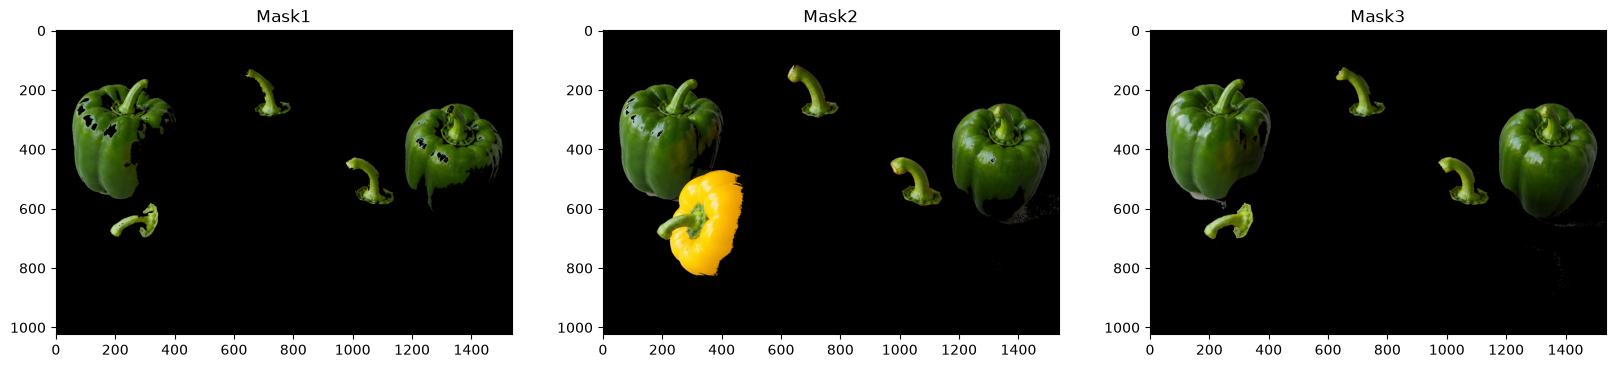

In [12]:
result_1 = cv2.bitwise_and(RGB_img, RGB_img, mask=mask_1)
result_2 = cv2.bitwise_and(RGB_img, RGB_img, mask=mask_2)
result_3 = cv2.bitwise_and(RGB_img, RGB_img, mask=mask_3)

plt.figure(figsize=[20,5])
plt.subplot(131); plt.imshow(result_1); plt.title("Mask1");
plt.subplot(132); plt.imshow(result_2); plt.title("Mask2");
plt.subplot(133); plt.imshow(result_3); plt.title("Mask3");

#### <div style="direction:rtl;text-align:right"> سوال پنجم؛ بررسی هیستوگرام و کنتراست </div>

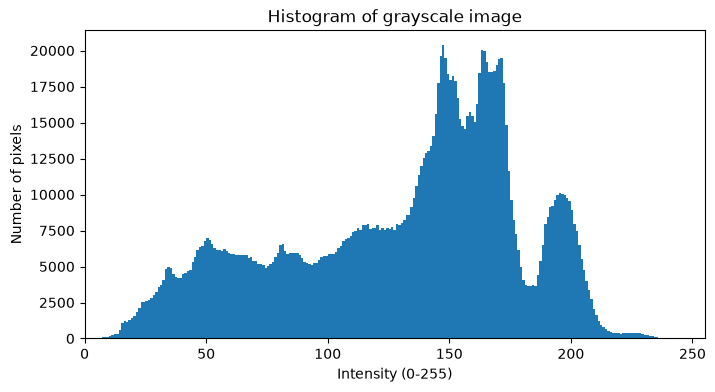

In [9]:
plt.figure(figsize=(8, 4))
plt.hist(gray.ravel(), bins=256, range=(0, 256))
plt.title("Histogram of grayscale image")
plt.xlabel("Intensity (0-255)")
plt.ylabel("Number of pixels")
plt.xlim(0, 255)
plt.show()

In [10]:
def rms_contrast(image):
    """RMS contrast = sqrt(mean((I - mean(I))^2)) روی شدت‌های نرمال‌شده در بازه 0 تا 1"""
    I = image.astype(np.float32) / 255.0
    return np.sqrt(np.mean((I - I.mean()) ** 2))

print(f"RMS contrast of original image: {rms_contrast(gray):.4f}")

RMS contrast of original image: 0.1906


In [11]:
def change_contrast(image, alpha):
    """alpha > 1: کنتراست بیشتر | alpha < 1: کنتراست کمتر
    پیکسل‌ها را حول میانگین تصویر کشش یا فشرده می‌کند."""
    mean = image.mean()
    out = mean + alpha * (image.astype(np.float32) - mean)
    return np.clip(out, 0, 255).astype(np.uint8)

high_contrast = change_contrast(gray, alpha=1.5)
low_contrast  = change_contrast(gray, alpha=0.5)

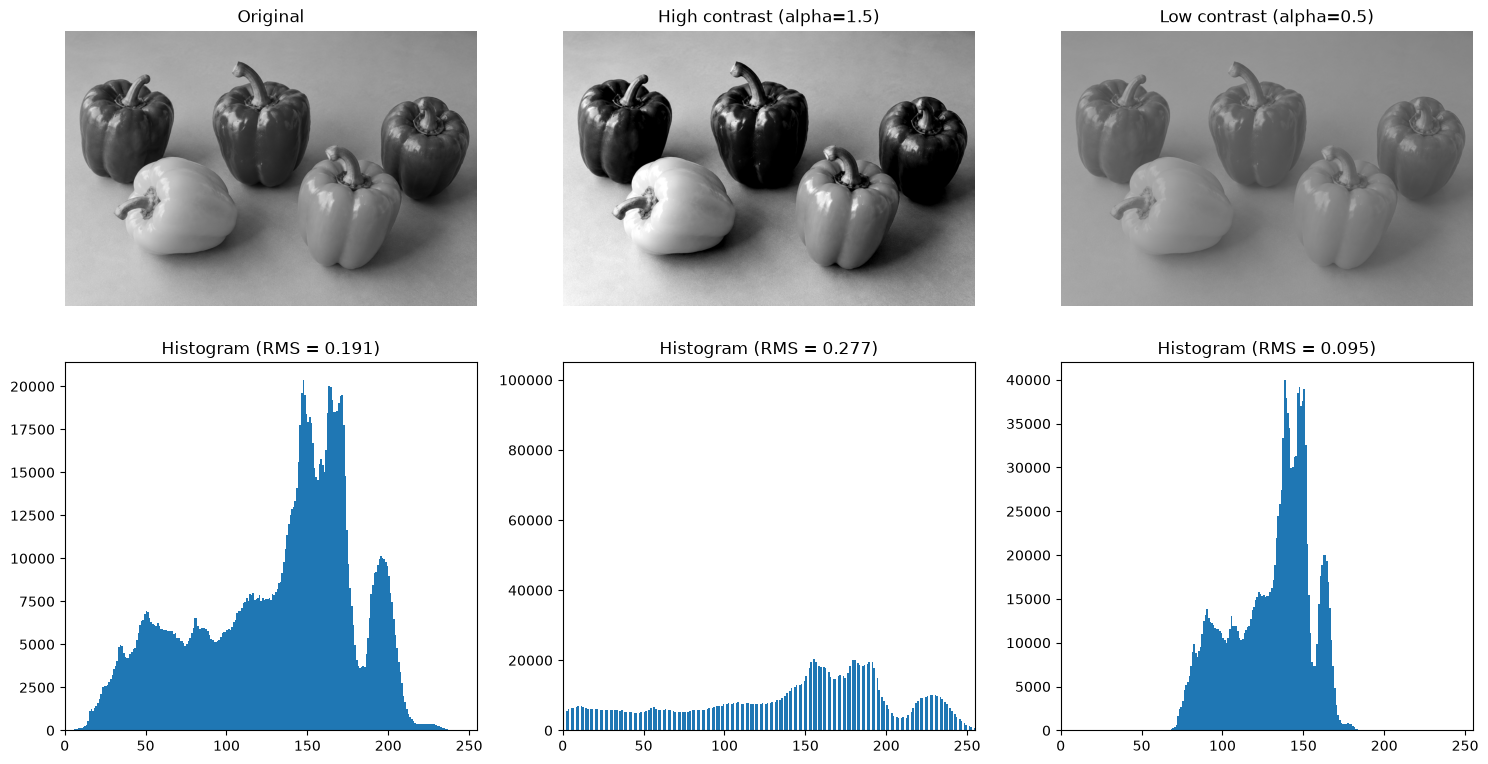

In [12]:
images = [
    ("Original", gray),
    ("High contrast (alpha=1.5)", high_contrast),
    ("Low contrast (alpha=0.5)", low_contrast),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, (title, im) in enumerate(images):
    # vmin و vmax مهم‌اند، وگرنه matplotlib خودش کنتراست را کش می‌دهد
    axes[0, i].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(title)
    axes[0, i].axis("off")

    axes[1, i].hist(im.ravel(), bins=256, range=(0, 256))
    axes[1, i].set_xlim(0, 255)
    axes[1, i].set_title(f"Histogram (RMS = {rms_contrast(im):.3f})")

plt.tight_layout()
plt.show()

In [13]:
base = rms_contrast(gray)

print(f"{'Image':28s} {'Mean':>8s} {'RMS':>8s} {'Change vs original':>20s}")
for title, im in images:
    rms = rms_contrast(im)
    change = (rms - base) / base * 100
    print(f"{title:28s} {im.mean():8.1f} {rms:8.4f} {change:+19.1f}%")

Image                            Mean      RMS   Change vs original
Original                        130.3   0.1906                +0.0%
High contrast (alpha=1.5)       130.7   0.2769               +45.3%
Low contrast (alpha=0.5)        129.9   0.0953               -50.0%


<div style="direction:rtl;text-align:right">

##### توزیع شدت روشنایی
هیستوگرام تصویر اصلی نشان می‌دهد پیکسل‌ها بیشتر در محدوده میانی متمرکز هستند. مقدار RMS Contrast تصویر اصلی برابر 0.19 است.

##### روش تغییر کنتراست
از رابطه `out = mean + alpha * (I - mean)` استفاده شد. این رابطه پیکسل‌ها را حول میانگین کشش (alpha>1) یا فشرده (alpha<1) می‌کند و میانگین روشنایی تقریباً ثابت می‌ماند، پس فقط کنتراست تغییر می‌کند و نه روشنایی کلی.

##### مقایسه
| تصویر | RMS | تغییر نسبت به اصلی |
|---|---|---|
| اصلی | 0.19 | 00% |
| پرکنتراست (α=1.5) | 0.28 | 45% |
| کم‌کنتراست (α=0.5) | 0.095 | -50% |

- در نسخه **کم‌کنتراست**، هیستوگرام باریک‌تر و دور میانگین فشرده شده و RMS دقیقاً حدود نصف شده است (به دلیل α=0.5).
- در نسخه **پرکنتراست**، هیستوگرام پهن‌تر می‌شود و RMS افزایش می‌یابد. چون مقادیر بیرون از بازه [0,255] برش (clip) می‌خورند، افزایش کمی کمتر از ۱.۵ برابر است و ممکن است روی دو لبه هیستوگرام (۰ و ۲۵۵) یک ستون بلند ببینیم.

</div>

#### <div style="direction:rtl;text-align:right"> سوال ششم؛ بهبود تصویر در شرایط نوری نامناسب </div>

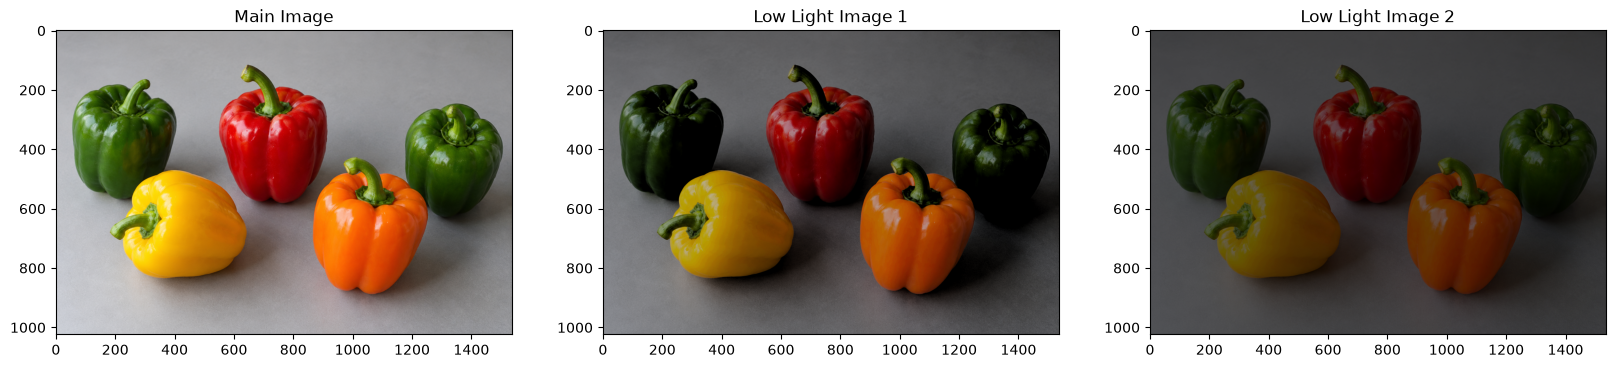

In [98]:
lowLight_img1 = HSV_img.copy()
lowLight_img1[:,:,2] = cv2.subtract(lowLight_img1[:, :, 2], 70)

lowLight_img2 = HSV_img.copy()
lowLight_img2[:,:,2] = (lowLight_img2[:, :, 2] * 0.4).astype(np.uint8)

plt.figure(figsize=[20,8])
plt.subplot(131); plt.imshow(RGB_img); plt.title('Main Image');
plt.subplot(132); plt.imshow(cv2.cvtColor(lowLight_img1, cv2.COLOR_HSV2RGB)); plt.title('Low Light Image 1');
plt.subplot(133); plt.imshow(cv2.cvtColor(lowLight_img2, cv2.COLOR_HSV2RGB)); plt.title('Low Light Image 2');

##### <div style="direction:rtl;text-align:right"> Histogram Equalization </div>

##### <div style="direction:rtl;text-align:right"> Histogram Stretching </div>

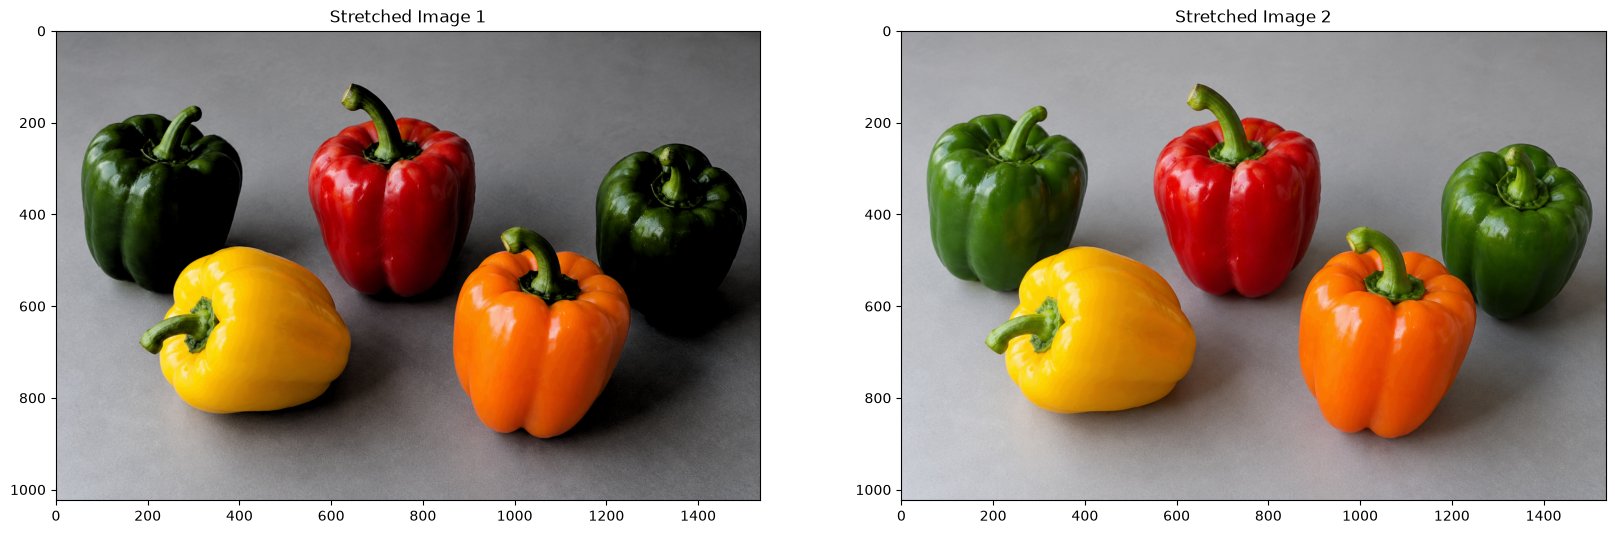

In [99]:
value_channel_1 = lowLight_img1[:,:,2] 
min_value_1 = np.min(value_channel_1); max_value_1 = np.max(value_channel_1);
stretched_value_1 = ((value_channel_1 - min_value_1) / (max_value_1 - min_value_1) * 255).astype(np.uint8)
lowLight_img1[:,:,2] = stretched_value_1

value_channel_2 = lowLight_img2[:,:,2]
min_value_2 = np.min(value_channel_2); max_value_2 = np.max(value_channel_2);
stretched_value_2 = ((value_channel_2 - min_value_2) / (max_value_2 - min_value_2) * 255).astype(np.uint8)
lowLight_img2[:,:,2] = stretched_value_2

plt.figure(figsize=[20,10])
plt.subplot(121); plt.imshow(cv2.cvtColor(lowLight_img1, cv2.COLOR_HSV2RGB)); plt.title('Stretched Image 1');
plt.subplot(122); plt.imshow(cv2.cvtColor(lowLight_img2, cv2.COLOR_HSV2RGB)); plt.title('Stretched Image 2');